# 03 — Deep learning from scratch: BiLSTM, TextCNN, Attention BiLSTM

Word-level torch classifiers with their own learned embeddings (shared
`<pad>=0 / <unk>=1` vocabulary scheme, 200-token inputs over the shekar
lemma tokens). The deployed checkpoints are evaluated **from disk, no
retraining**, on the leak-free held-out set
(`aitextd.splits.deployed_heldout_frame()` — v1-test documents present in the
v2 corpus), with the shared `aitextd.metrics.evaluation_report` battery.

In [1]:
import numpy as np
import pandas as pd
import torch

from aitextd import loaders, metrics, paths, plots, registry, splits
from aitextd.training import encode_tokens, predict_probs

SEED = 42
RUN_TRAINING = False  # True: rerun the complete training procedure below (~1-2 h on CPU)

torch.manual_seed(SEED)
torch.set_num_threads(8)

/home/ehsan/Mount/AITextDetection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
heldout = splits.deployed_heldout_frame()
tokenized = splits.v1_tokens()
heldout_tokens = [tokenized[row] for row in heldout["v1_row"]]
y_held = heldout["label_binary"].to_numpy()
print(f"held-out set: {len(heldout)} documents "
      f"(human {int((y_held == 0).sum())} / AI {int((y_held == 1).sum())})")

held-out set: 4056 documents (human 1949 / AI 2107)


## Standard training procedure (complete, flag-guarded)

The **complete** loop for the family: one shared vocabulary over the v1
training tokens -> encode -> `fit_classifier` (BCE + Adam, per-epoch eval F1,
best weights kept) -> save in the loader format -> refresh `models.json` —
repeated for BiLSTM, TextCNN and Attention BiLSTM with their recorded
hyperparameters.

**Not executed here** (`RUN_TRAINING = False`): the deployed checkpoints
provide the numbers below, and the evaluation cells run unchanged whether this
cell is skipped or rerun with `RUN_TRAINING = True`.

In [ ]:
if RUN_TRAINING:
    import joblib

    from aitextd.architectures import AttentionBiLSTMClassifier, BiLSTMClassifier, TextCNNClassifier
    from aitextd.training import build_vocab, fit_classifier, save_checkpoint

    indices = joblib.load(paths.DATA_DIR / "split_indices.joblib")
    y_all = pd.read_csv(paths.PROCESSED_CSV, usecols=["aiGenerated"])["aiGenerated"].to_numpy()
    train_idx, test_idx = indices["train_idx"], indices["test_idx"]
    train_tokens = [tokenized[i] for i in train_idx]
    test_tokens = [tokenized[i] for i in test_idx]

    MAX_LEN = 200
    vocab = build_vocab(train_tokens)
    X_train_seq = encode_tokens(train_tokens, vocab, MAX_LEN)
    X_test_seq = encode_tokens(test_tokens, vocab, MAX_LEN)

    def build(model_cls, config):
        """Instantiate one architecture from its recorded config."""
        if model_cls is TextCNNClassifier:
            return TextCNNClassifier(
                len(vocab), config["embed_dim"], config["n_filters"],
                tuple(config["kernel_sizes"]), pad_idx=0, dropout=config["dropout"],
            )
        if model_cls is AttentionBiLSTMClassifier:
            return AttentionBiLSTMClassifier(
                len(vocab), config["embed_dim"], config["hidden_dim"],
                pad_idx=0, dropout=config["dropout"],
            )
        return BiLSTMClassifier(len(vocab), config["embed_dim"], config["hidden_dim"], pad_idx=0)

    specs = {
        "bilstm": (BiLSTMClassifier, {"embed_dim": 128, "hidden_dim": 128}, "lstmModel.pt", 5),
        "textcnn": (TextCNNClassifier, {"embed_dim": 128, "n_filters": 100, "kernel_sizes": [3, 4, 5], "dropout": 0.3}, "textcnnModel.pt", 8),
        "attention_bilstm": (AttentionBiLSTMClassifier, {"embed_dim": 128, "hidden_dim": 128, "dropout": 0.3}, "attnBilstmModel.pt", 4),
    }

    training_info = {
        "totalSamples": len(train_idx) + len(test_idx), "trainSamples": len(train_idx),
        "testSamples": len(test_idx), "featureCount": len(vocab), "testSplitRatio": 0.2,
        "randomSeed": SEED, "dataset": "persian_ai_generated_final.csv + blogs.csv",
    }
    for model_id, (model_cls, extra, filename, epochs) in specs.items():
        config = {"max_len": MAX_LEN, "pad_idx": 0, "unk_idx": 1, **extra}
        print(f"training {model_id} (vocab {len(vocab)}) ...", flush=True)
        model, _ = fit_classifier(
            build(model_cls, config),
            X_train_seq, y_all[train_idx], X_test_seq, y_all[test_idx], epochs,
        )
        save_checkpoint(paths.model_path(filename), model, vocab=vocab, config=config)
        registry.refresh_entry(
            model_id,
            metrics.evaluate(y_all[test_idx], predict_probs(model, X_test_seq)),
            training_info,
        )
else:
    print("RUN_TRAINING=False — the deployed checkpoints are used below")

In [3]:
reports, probs_held = {}, {}

def score_vocabulary_model(bundle):
    """Held-out AI probabilities for one checkpoint, with the serving encoding:
    whitespace tokens -> vocab ids -> pad/truncate to the checkpoint max_len."""
    X = encode_tokens(heldout_tokens, bundle["vocab"], bundle["config"]["max_len"])
    return predict_probs(bundle["model"], X)

In [4]:
bilstm = loaders.load_lstm_model({"filename": "lstmModel.pt"})
probs_held["bilstm"] = score_vocabulary_model(bilstm)
reports["bilstm"] = metrics.evaluation_report(y_held, probs_held["bilstm"])
print("evaluated bilstm")

evaluated bilstm


In [5]:
textcnn = loaders.load_textcnn_model({"filename": "textcnnModel.pt"})
probs_held["textcnn"] = score_vocabulary_model(textcnn)
reports["textcnn"] = metrics.evaluation_report(y_held, probs_held["textcnn"])
print("evaluated textcnn")

evaluated textcnn


In [6]:
attention_bilstm = loaders.load_attention_bilstm_model({"filename": "attnBilstmModel.pt"})
probs_held["attention_bilstm"] = score_vocabulary_model(attention_bilstm)
reports["attention_bilstm"] = metrics.evaluation_report(y_held, probs_held["attention_bilstm"])
print("evaluated attention_bilstm")

evaluated attention_bilstm


In [7]:
metrics.evaluation_table(reports, metrics.RANKING_COLUMNS)

,roc_auc,pr_auc,pauc_5,tpr_at_fpr_1,tpr_at_fpr_5,fpr_at_tpr_90
model,,,,,,
bilstm,0.9973,0.9980,0.9798,0.9758,0.9934,0.0010
textcnn,0.9994,0.9995,0.9937,0.9934,0.9981,0.0005
attention_bilstm,0.9982,0.9987,0.9841,0.9862,0.9962,0.0010


In [8]:
metrics.evaluation_table(reports, metrics.THRESHOLD_COLUMNS)

,accuracy,balanced_accuracy,macro_f1,mcc,kappa,precision,recall,f1,fpr
model,,,,,,,,,
bilstm,0.9825,0.9827,0.9825,0.9650,0.9650,0.9894,0.9767,0.9830,0.0113
textcnn,0.9916,0.9916,0.9916,0.9832,0.9832,0.9910,0.9929,0.9919,0.0097
attention_bilstm,0.9879,0.9880,0.9879,0.9758,0.9758,0.9909,0.9858,0.9883,0.0097


In [9]:
metrics.evaluation_table(reports, metrics.CALIBRATION_COLUMNS)

,ece,ace,mce,brier,nll,calibration_slope,calibration_intercept
model,,,,,,,
bilstm,0.0143,0.0077,0.7781,0.0151,0.0831,0.4931,0.4182
textcnn,0.0057,0.0031,0.6305,0.0065,0.0268,0.7139,-0.3559
attention_bilstm,0.0066,0.0041,0.4000,0.0100,0.0425,0.8452,0.3810


<Axes: title={'left': 'BiLSTM family — leak-free held-out set'}>

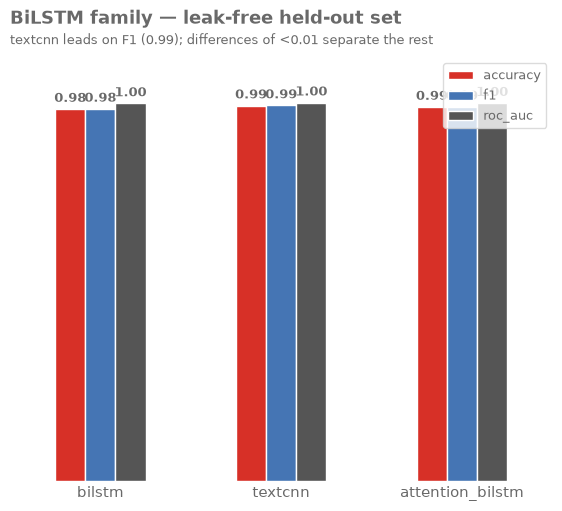

In [10]:
plots.metric_bars(reports, "BiLSTM family — leak-free held-out set")

<Axes: title={'center': 'bilstm'}, xlabel='prediction'>

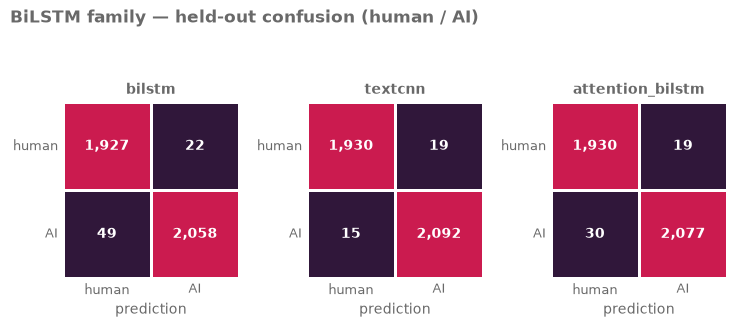

In [11]:
plots.confusion_grid(reports, "BiLSTM family — held-out confusion (human / AI)")

<Axes: title={'left': 'BiLSTM family — ROC, low-FPR region'}, xlabel='False Positive Rate (log scale)', ylabel='True Positive Rate'>

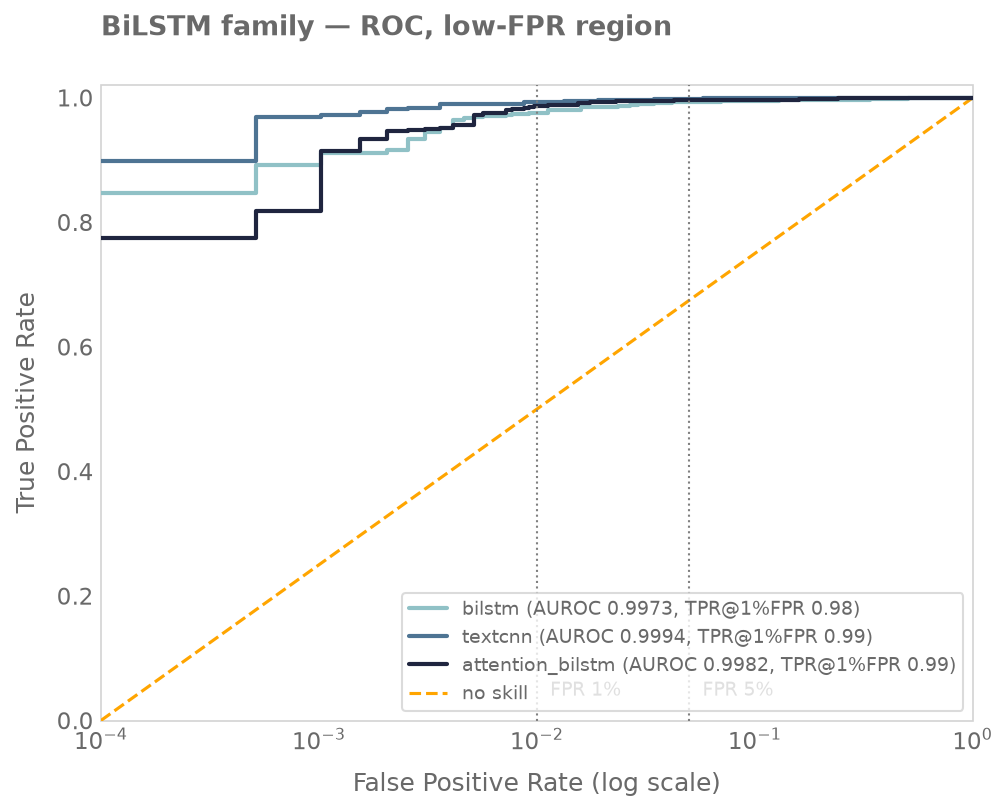

In [12]:
plots.roc_curves_log(y_held, probs_held, "BiLSTM family — ROC, low-FPR region")

<Axes: title={'left': 'bilstm\nECE 0.015'}, ylabel='empirical accuracy'>

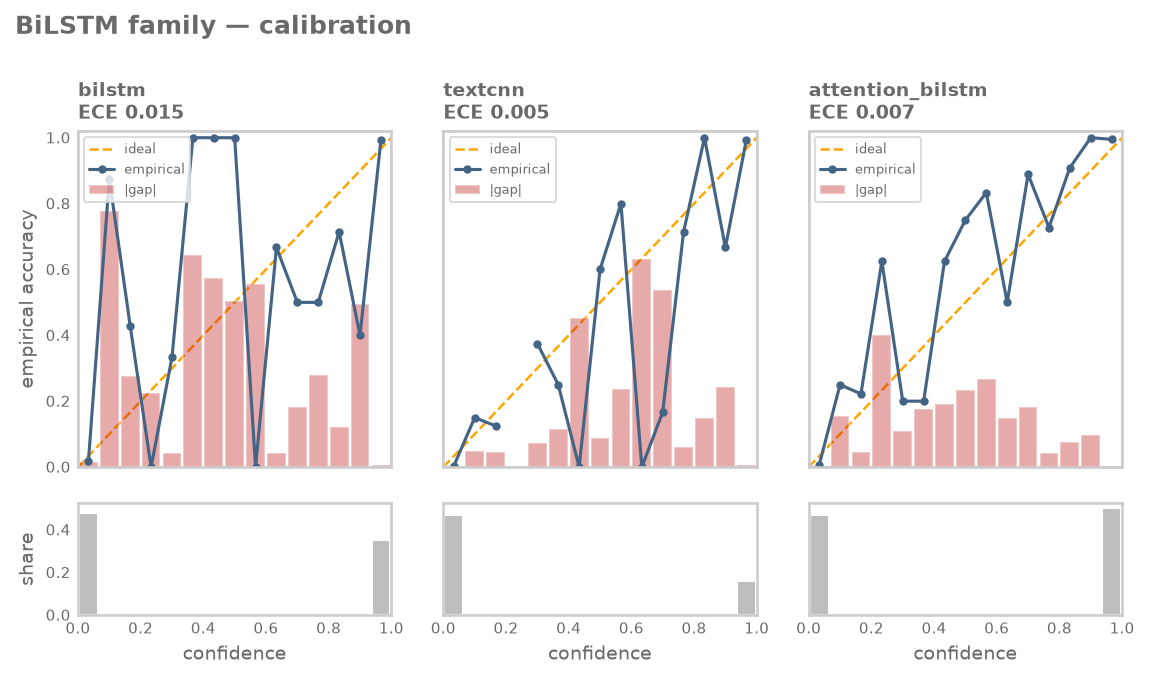

In [13]:
plots.reliability_grid(y_held, probs_held, title="BiLSTM family — calibration")

<Axes: title={'left': 'bilstm'}, xlabel='AI probability', ylabel='density'>

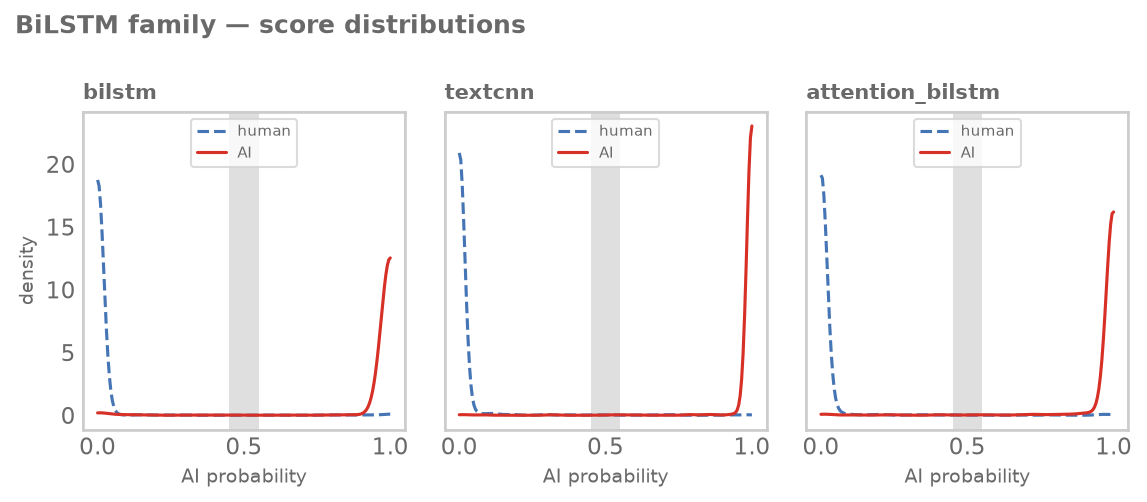

In [14]:
plots.score_distributions(y_held, probs_held, "BiLSTM family — score distributions")

## Summary

- Same evaluation battery and chart set as notebook 02, one family of three
  word-level models.
- Word-level models see only the first 200 lemma tokens, so their calibration
  and low-FPR behaviour trade off against the classical models' full-document
  TF-IDF view — compare across notebooks, not within.